EXPLORATORY DATA ANALYSIS ON A DATASET 

Objective:

The main goal of this assignment is to conduct a thorough exploratory analysis of the "cardiographic.csv" dataset to uncover insights, identify patterns, and understand the dataset's underlying structure. You will use statistical summaries, visualizations, and data manipulation techniques to explore the dataset comprehensively.
Dataset:


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

1.	Data Cleaning and Preparation:

●	Load the dataset into a data frame or equivalent data structure.

●	Handle missing values appropriately (e.g., imputation, deletion).

●	Identify and correct any inconsistencies in data types (e.g., numerical values stored as strings).

●	Detect and treat outliers if necessary.


In [3]:
df=pd.read_csv('Cardiotocographic.csv')

In [4]:
df.head()

,LB,AC,FM,UC,DL,DS,DP,ASTV,MSTV,ALTV,MLTV,Width,Tendency,NSP
0,120.000000,0.000000,0.0,0.000000,0.000000,0.0,0.0,73.0,0.5,43.0,2.4,64.0,0.999926,2.0
1,132.000000,0.006380,0.0,0.006380,0.003190,0.0,0.0,17.0,2.1,0.0,10.4,130.0,0.000000,1.0
2,133.000000,0.003322,0.0,0.008306,0.003322,0.0,0.0,16.0,2.1,0.0,13.4,130.0,0.000000,1.0
3,134.000000,0.002561,0.0,0.007742,0.002561,0.0,0.0,16.0,2.4,0.0,23.0,117.0,1.000000,1.0
4,131.948232,0.006515,0.0,0.008143,0.000000,0.0,0.0,16.0,2.4,0.0,19.9,117.0,1.000000,1.0


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2126 entries, 0 to 2125
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   LB        2105 non-null   float64
 1   AC        2106 non-null   float64
 2   FM        2126 non-null   float64
 3   UC        2126 non-null   float64
 4   DL        2126 non-null   float64
 5   DS        2105 non-null   float64
 6   DP        2105 non-null   float64
 7   ASTV      2126 non-null   float64
 8   MSTV      2126 non-null   float64
 9   ALTV      2126 non-null   float64
 10  MLTV      2105 non-null   float64
 11  Width     2105 non-null   float64
 12  Tendency  2105 non-null   float64
 13  NSP       2105 non-null   float64
dtypes: float64(14)
memory usage: 232.7 KB


In [6]:
df.duplicated().sum()

np.int64(2)

In [7]:
df=df.drop_duplicates()

In [8]:
df.isnull().sum()

LB          21
AC          20
FM           0
UC           0
DL           0
DS          21
DP          21
ASTV         0
MSTV         0
ALTV         0
MLTV        21
Width       21
Tendency    21
NSP         21
dtype: int64

In [9]:
#d_cols=df[['LB','Width','Tendency','NSP']]
#c_cols=df[['AC','DS','DP','MLTV']]

In [10]:
df[['LB','Width','Tendency','NSP']]=df[['LB','Width','Tendency','NSP']].fillna(df[['LB','Width','Tendency','NSP']].mode().iloc[0])
df[['AC','DS','DP','MLTV']]=df[['AC','DS','DP','MLTV']].fillna(df[['AC','DS','DP','MLTV']].mean())

In [11]:
df.isnull().sum()

LB          0
AC          0
FM          0
UC          0
DL          0
DS          0
DP          0
ASTV        0
MSTV        0
ALTV        0
MLTV        0
Width       0
Tendency    0
NSP         0
dtype: int64

In [12]:
df.duplicated().sum()

np.int64(0)

In [13]:
df.info()

<class 'pandas.DataFrame'>
Index: 2124 entries, 0 to 2125
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   LB        2124 non-null   float64
 1   AC        2124 non-null   float64
 2   FM        2124 non-null   float64
 3   UC        2124 non-null   float64
 4   DL        2124 non-null   float64
 5   DS        2124 non-null   float64
 6   DP        2124 non-null   float64
 7   ASTV      2124 non-null   float64
 8   MSTV      2124 non-null   float64
 9   ALTV      2124 non-null   float64
 10  MLTV      2124 non-null   float64
 11  Width     2124 non-null   float64
 12  Tendency  2124 non-null   float64
 13  NSP       2124 non-null   float64
dtypes: float64(14)
memory usage: 248.9 KB


In [14]:
df.columns

Index(['LB', 'AC', 'FM', 'UC', 'DL', 'DS', 'DP', 'ASTV', 'MSTV', 'ALTV',
       'MLTV', 'Width', 'Tendency', 'NSP'],
      dtype='str')

In [15]:
features=df.drop(columns=['NSP'])

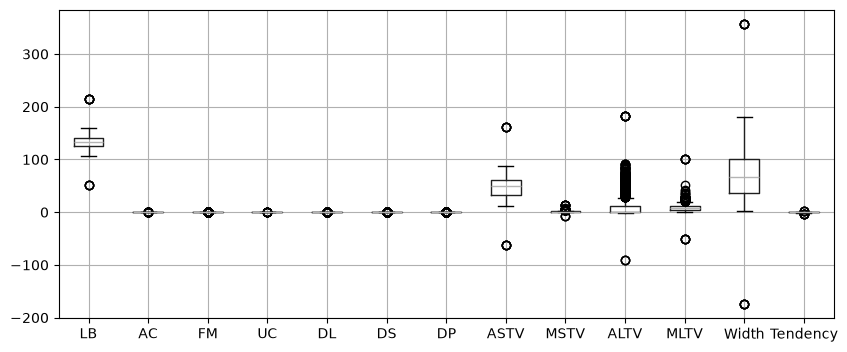

In [16]:
plt.figure(figsize=(10,4))
features.boxplot()
plt.show()

In [17]:
def outlier_capping(df,col):
    Q1=df[col].quantile(0.25)
    Q3=df[col].quantile(0.75)
    IQR=Q3-Q1
    lower_extreme=Q1-1.5*IQR
    upper_extreme=Q3+1.5*IQR
    df[col]=df[col].apply(lambda x: lower_extreme if x<lower_extreme else upper_extreme if x>upper_extreme else x)
for col in features:
    outlier_capping(features,col)

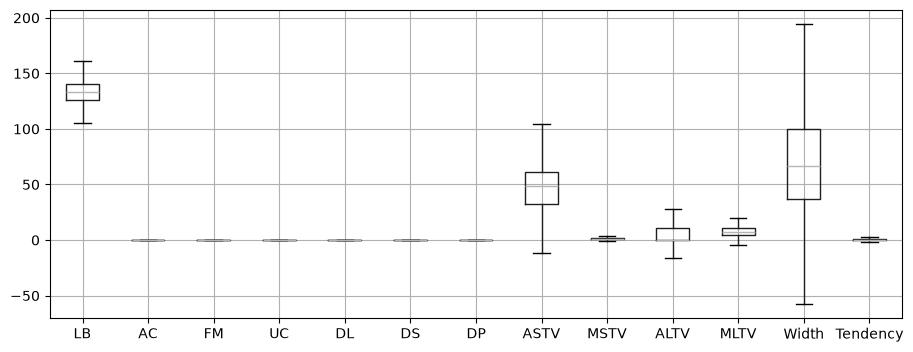

In [18]:
plt.figure(figsize=(11,4))
features.boxplot()
plt.show()

2.	Statistical Summary:                                                                                                                
●	Provide a statistical summary for each variable in the dataset, including measures of central tendency (mean, median) and dispersion (standard deviation, interquartile range).                                                                                                     
●	Highlight any interesting findings from this summary.


In [20]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
LB,2124.0,133.338641,11.212447,51.842487,126.000000,133.000000,140.000000,214.000000
AC,2124.0,0.003220,0.004371,-0.019284,0.000000,0.001668,0.005612,0.038567
FM,2124.0,0.009904,0.067571,-0.480634,0.000000,0.000000,0.002568,0.961268
UC,2124.0,0.004394,0.003340,-0.014925,0.001858,0.004486,0.006536,0.030002
DL,2124.0,0.001897,0.003344,-0.015393,0.000000,0.000000,0.003292,0.030769
DS,2124.0,0.000003,0.000141,-0.001353,0.000000,0.000000,0.000000,0.002706
DP,2124.0,0.000175,0.000836,-0.005348,0.000000,0.000000,0.000000,0.010695
ASTV,2124.0,47.012459,18.812403,-63.000000,32.000000,49.000000,61.000000,162.000000
MSTV,2124.0,1.364345,1.174084,-6.600000,0.700000,1.200000,1.700000,13.800000
ALTV,2124.0,10.295650,21.212676,-91.000000,0.000000,0.000000,11.000000,182.000000


In [23]:
summary_stats=df.describe().T

# Calculate the Interquartile Range (IQR) (75th percentile - 25th percentile)
summary_stats['IQR']=summary_stats['75%']-summary_stats['25%']

summary_stats=summary_stats.rename(columns={'50%':'Median'})

final_summary=summary_stats[['mean', 'Median', 'std', 'IQR']]

In [24]:
#Displaying the final summary table
final_summary

,mean,Median,std,IQR
LB,133.338641,133.000000,11.212447,14.000000
AC,0.003220,0.001668,0.004371,0.005612
FM,0.009904,0.000000,0.067571,0.002568
UC,0.004394,0.004486,0.003340,0.004678
DL,0.001897,0.000000,0.003344,0.003292
DS,0.000003,0.000000,0.000141,0.000000
DP,0.000175,0.000000,0.000836,0.000000
ASTV,47.012459,49.000000,18.812403,29.000000
MSTV,1.364345,1.200000,1.174084,1.000000
ALTV,10.295650,0.000000,21.212676,11.000000


3.	Data Visualization:

●	Create histograms or boxplots to visualize the distributions of various numerical variables.

●	Use bar charts or pie charts to display the frequency of categories for categorical variables.

●	Generate scatter plots or correlation heatmaps to explore relationships between pairs of variables.

●	Employ advanced visualization techniques like pair plots, or violin plots for deeper insights.


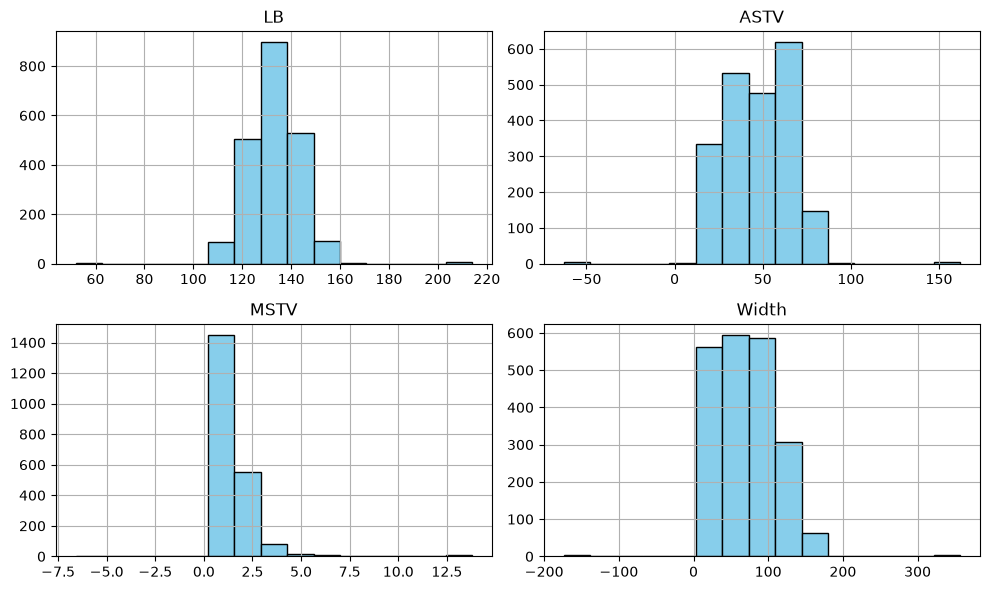

In [45]:
#Create histograms or boxplots to visualize the distributions of various numerical variables.
num_cols=['LB','ASTV','MSTV','Width']
df[num_cols].hist(bins=15,figsize=(10,6),color='skyblue',edgecolor='black')
plt.tight_layout()

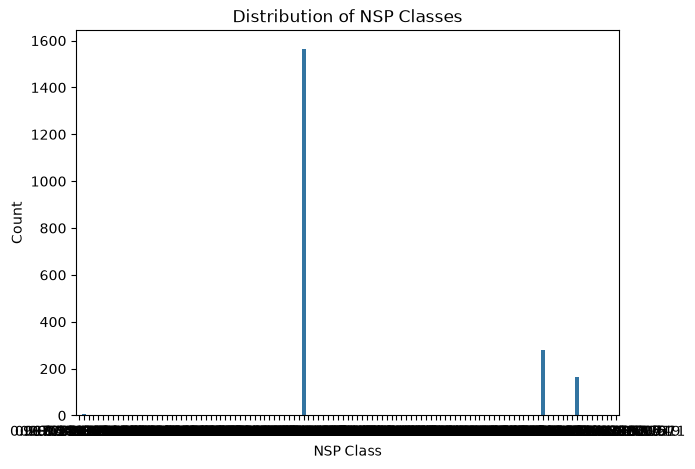

In [46]:
#Use bar charts or pie charts to display the frequency of categories for categorical variables.
plt.figure(figsize=(7, 5))

sns.countplot(df,x='NSP')

plt.title("Distribution of NSP Classes")
plt.xlabel("NSP Class")
plt.ylabel("Count")

plt.show()

<Axes: >

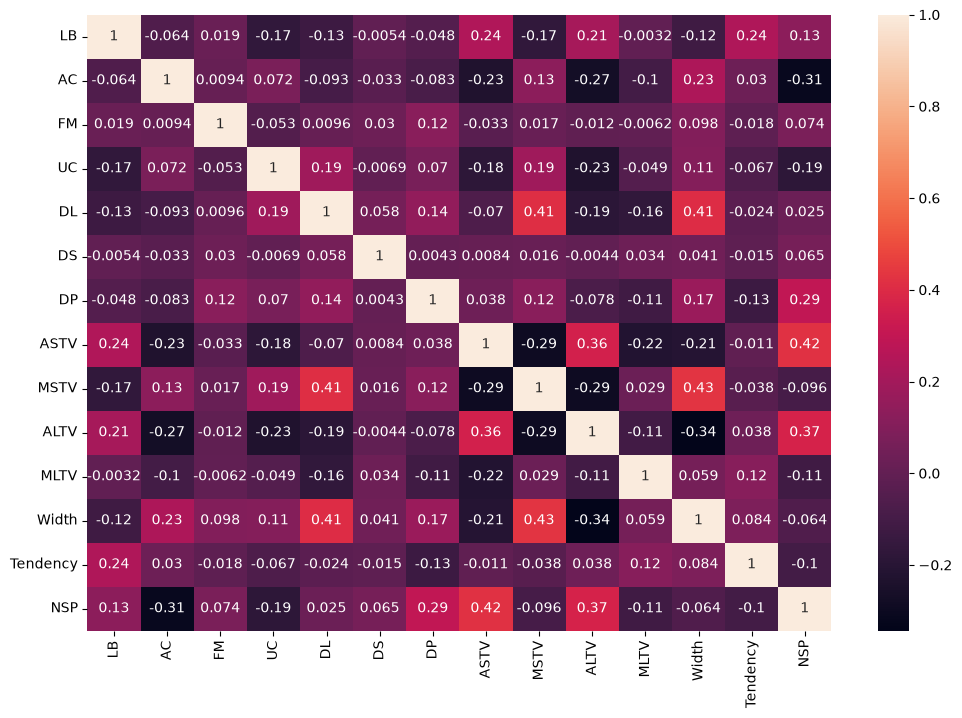

In [48]:
#Generate scatter plots or correlation heatmaps to explore relationships between pairs of variables.
plt.figure(figsize=(12,8))
corr=df.corr()
sns.heatmap(corr,annot=True)

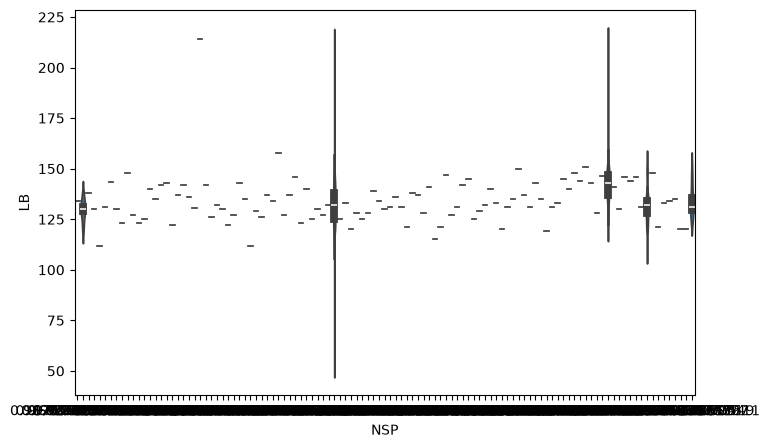

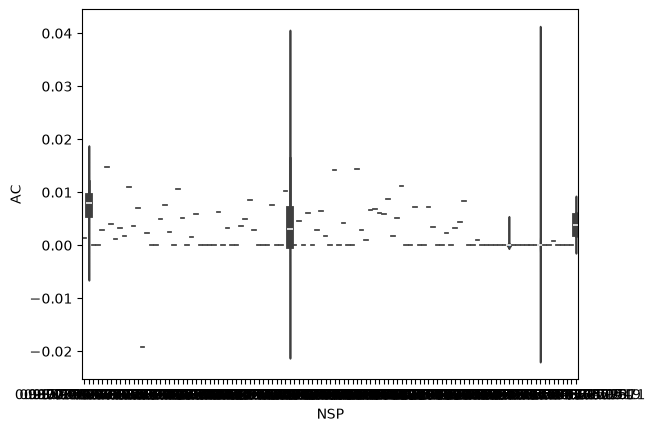

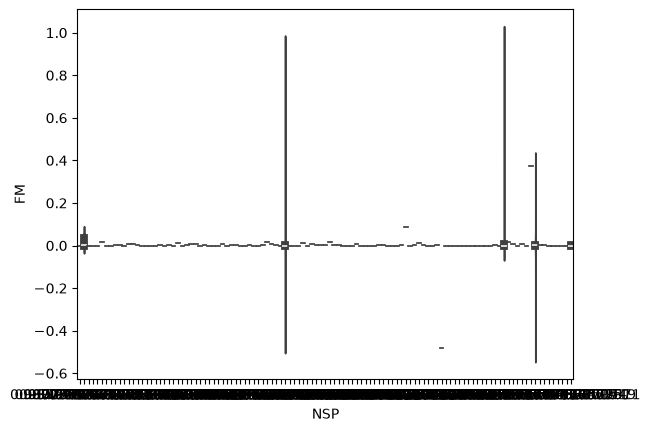

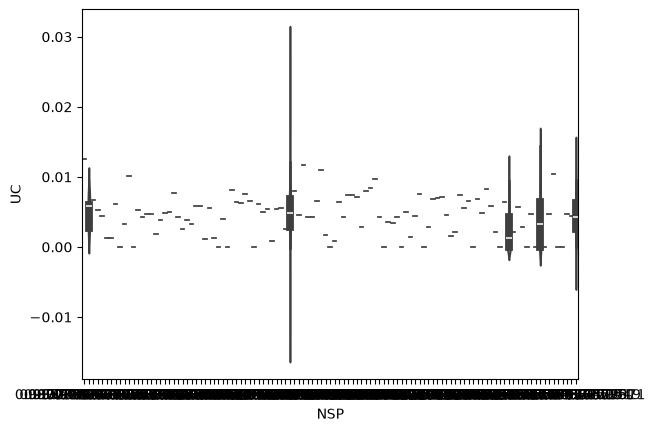

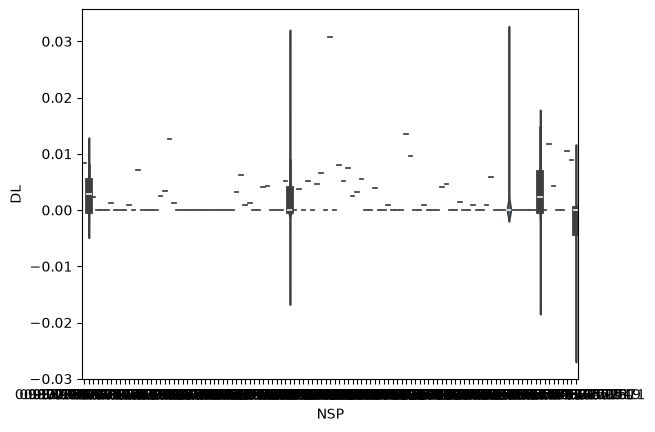

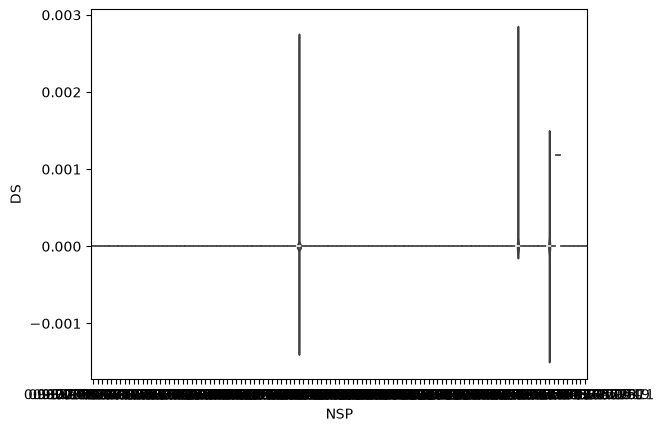

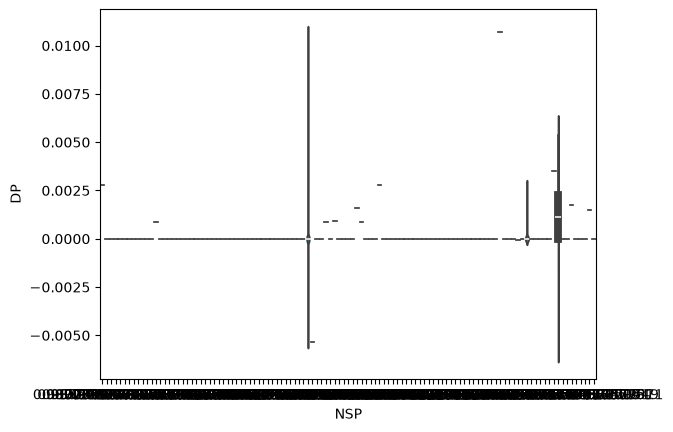

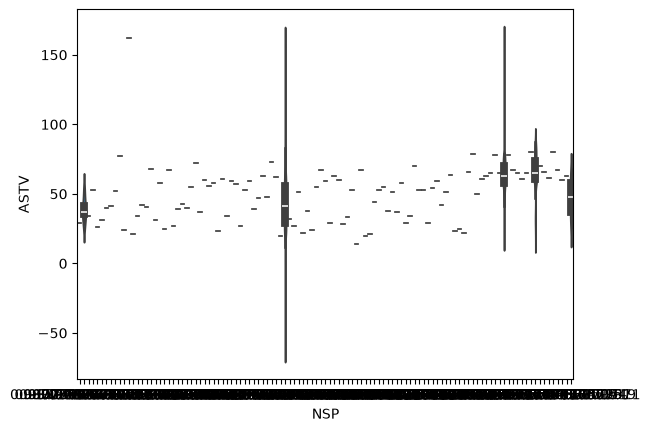

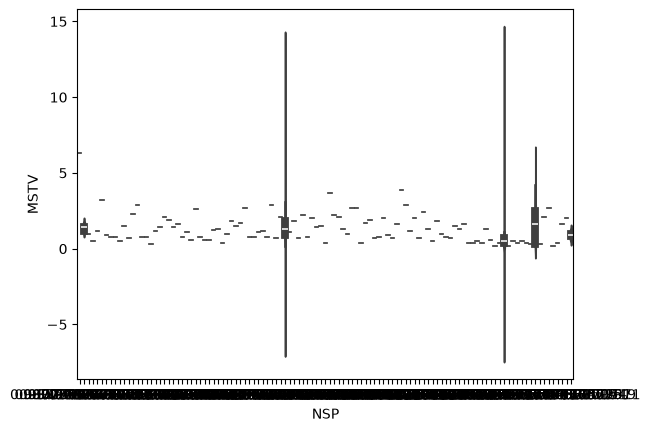

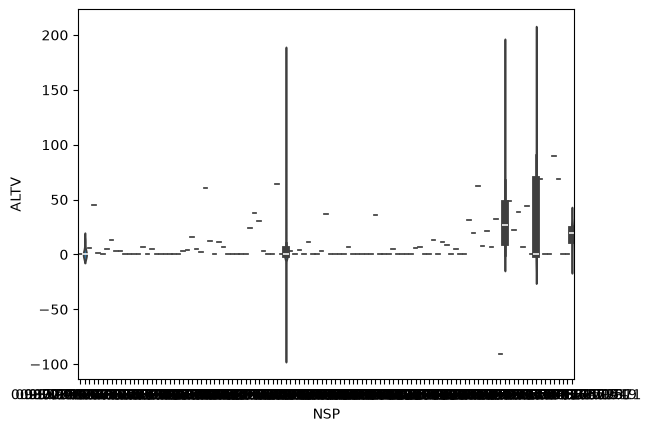

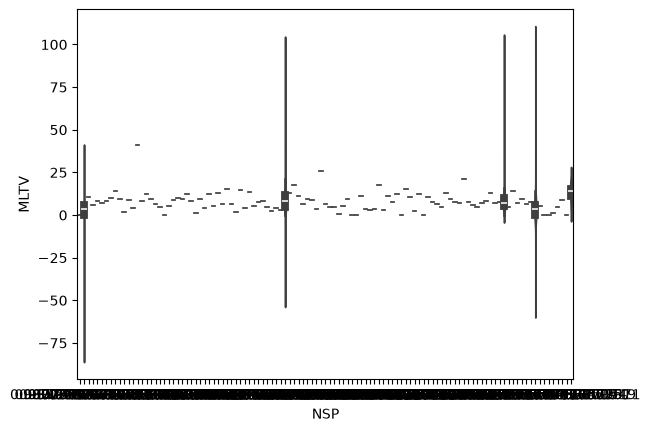

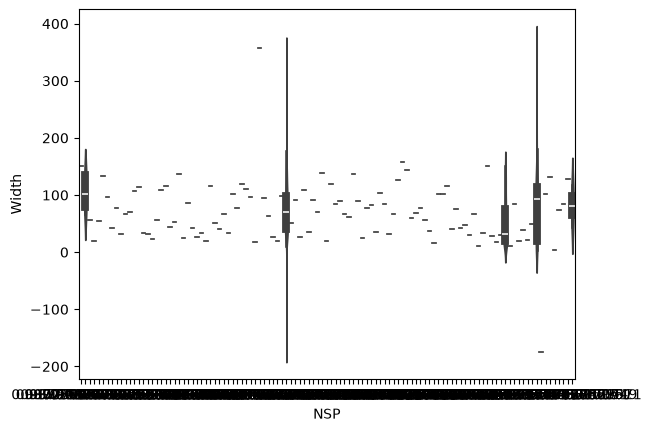

In [61]:
#Employ advanced visualization techniques like pair plots, or violin plots for deeper insights.
cols_to_plot=[col for col in df.columns if col not in ['NSP', 'Tendency']]
plt.figure(figsize=(8,5))
for i in cols_to_plot:
    sns.violinplot(data=df,x='NSP',y=i)
    plt.show()

4.	Pattern Recognition and Insights:

●	Identify any correlations between variables and discuss their potential implications.

●	Look for trends or patterns over time if temporal data is available.


In [62]:
df.corr()

,LB,AC,FM,UC,DL,DS,DP,ASTV,MSTV,ALTV,MLTV,Width,Tendency,NSP
LB,1.000000,-0.063568,0.018839,-0.166669,-0.126585,-0.005439,-0.047726,0.241667,-0.169310,0.210769,-0.003225,-0.117842,0.236976,0.132003
AC,-0.063568,1.000000,0.009406,0.071552,-0.093330,-0.033109,-0.083330,-0.231058,0.133903,-0.271204,-0.104658,0.231303,0.029984,-0.313652
FM,0.018839,0.009406,1.000000,-0.053386,0.009641,0.029896,0.121248,-0.032838,0.017061,-0.012005,-0.006156,0.097611,-0.017888,0.074389
UC,-0.166669,0.071552,-0.053386,1.000000,0.189737,-0.006942,0.070348,-0.182379,0.189685,-0.227881,-0.048754,0.105606,-0.067314,-0.185766
DL,-0.126585,-0.093330,0.009641,0.189737,1.000000,0.058429,0.144853,-0.069907,0.410216,-0.187275,-0.164942,0.406676,-0.024180,0.024634
DS,-0.005439,-0.033109,0.029896,-0.006942,0.058429,1.000000,0.004282,0.008414,0.016079,-0.004400,0.034366,0.040723,-0.015390,0.065327
DP,-0.047726,-0.083330,0.121248,0.070348,0.144853,0.004282,1.000000,0.037955,0.119270,-0.077760,-0.113993,0.174777,-0.130355,0.294091
ASTV,0.241667,-0.231058,-0.032838,-0.182379,-0.069907,0.008414,0.037955,1.000000,-0.293820,0.357310,-0.219225,-0.207186,-0.011289,0.420738
MSTV,-0.169310,0.133903,0.017061,0.189685,0.410216,0.016079,0.119270,-0.293820,1.000000,-0.291979,0.028653,0.429995,-0.038010,-0.095881
ALTV,0.210769,-0.271204,-0.012005,-0.227881,-0.187275,-0.004400,-0.077760,0.357310,-0.291979,1.000000,-0.107331,-0.343253,0.038019,0.366318


In [ ]:
#Calculate the correlation matrix
corr_matrix = df.corr()

#Unstack the matrix, sort values, and drop self-correlations
sorted_corrs = corr_matrix.unstack().sort_values(ascending=False)
sorted_corrs = sorted_corrs[sorted_corrs != 1.0]

#Display the top 10 positive and top 10 negative correlations
print("Top Positive Correlations:\n", sorted_corrs.head(10)[::2])
print("\nTop Negative Correlations:\n", sorted_corrs.tail(10)[::2])

Top Positive Correlations:
 MSTV  Width    0.429995
NSP   ASTV     0.420738
MSTV  DL       0.410216
DL    Width    0.406676
ALTV  NSP      0.366318
dtype: float64

Top Negative Correlations:
 ALTV   AC     -0.271204
MSTV   ALTV   -0.291979
       ASTV   -0.293820
AC     NSP    -0.313652
Width  ALTV   -0.343253
dtype: float64


In [67]:
print("""
Analysis of temporal trends was not conducted because the dataset consists of aggregated cross-sectional data \nand lacks any timestamp or sequential time-series variables
""")


Analysis of temporal trends was not conducted because the dataset consists of aggregated cross-sectional data 
and lacks any timestamp or sequential time-series variables



1.	Conclusion:

●	Summarize the key insights and patterns discovered through your exploratory analysis.

●	Discuss how these findings could impact decision-making or further analyses.


In [1]:
print("""  
Through our exploratory analysis of the cardiographic dataset, we successfully cleaned the data by handling missing values and capping \noutliers. By visualizing the features and checking correlations, we discovered that certain metrics like abnormal short term variability (ASTV) \nand prolonged decelerations(DP) are strong warning signs of fetal distress. Ultimately, these insights can help \nhealthcare providers make faster triage decisions during fetal monitoring, and this thoroughly cleaned data is now perfectly prepared \nfor building predictive machine learning models in future analyses.
""")

  
Through our exploratory analysis of the cardiographic dataset, we successfully cleaned the data by handling missing values and capping 
outliers. By visualizing the features and checking correlations, we discovered that certain metrics like abnormal short term variability (ASTV) 
and prolonged decelerations(DP) are strong warning signs of fetal distress. Ultimately, these insights can help 
healthcare providers make faster triage decisions during fetal monitoring, and this thoroughly cleaned data is now perfectly prepared 
for building predictive machine learning models in future analyses.

